# UCS420 Lab Assignment 9 — NLP Text Preprocessing


In [1]:
%pip install -q nltk pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
ROLL_NO = 1024170298
NAME = input("Enter your name: ").strip()

import nltk
required_nltk_data = {
    "punkt": "tokenizers/punkt",
    "punkt_tab": "tokenizers/punkt_tab",
    "stopwords": "corpora/stopwords",
    "wordnet": "corpora/wordnet",
    "omw-1.4": "corpora/omw-1.4",
    "averaged_perceptron_tagger": "taggers/averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng": "taggers/averaged_perceptron_tagger_eng",
}
missing_nltk_data = []
for package, resource in required_nltk_data.items():
    try:
        nltk.data.find(resource)
    except LookupError:
        try:
            if not nltk.download(package, quiet=True):
                missing_nltk_data.append(package)
        except Exception:
            missing_nltk_data.append(package)
assert ROLL_NO > 0 and NAME, "Enter your name first"
if missing_nltk_data:
    print("Some NLTK data could not be downloaded because the network is unavailable:", ", ".join(missing_nltk_data))
    print("Resource-free fallbacks will keep tokenization and analysis running.")
else:
    print("All required NLTK data is available.")


All required NLTK data is available.


### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import nltk
import string
import re
from nltk.tokenize import sent_tokenize as nltk_sent_tokenize, word_tokenize as nltk_word_tokenize, TreebankWordTokenizer
from nltk.corpus import stopwords

def sent_tokenize(text):
    try:
        return nltk_sent_tokenize(text)
    except LookupError:
        return [part for part in re.split(r"(?<=[.!?])\s+", text.strip()) if part]

def word_tokenize(text):
    try:
        return nltk_word_tokenize(text)
    except LookupError:
        return TreebankWordTokenizer().tokenize(text)

try:
    STOP = set(stopwords.words("english"))
    stopwords_source = "NLTK stopwords corpus"
except LookupError:
    STOP = set("i me my myself we our ours ourselves you your yours yourself yourselves he him his himself she her hers herself it its itself they them their theirs what which who whom this that these those am is are was were be been being have has had having do does did doing a an the and but if or because as until while of at by for with about against between into through during before after above below to from up down in out on off over under again further then once here there when where why how all any both each few more most other some such no nor not only own same so than too very can will just don should now".split())
    stopwords_source = "built-in offline English list"
print("Stopwords source:", stopwords_source)

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}


Stopwords source: NLTK stopwords corpus


In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170298   Name: Pranav   Fingerprint: EFDD50DE   Tickets: 15

Ticket_ID                                                                          Ticket_Text
      T01           Password stopped responding since yesterday. It works on another computer.
      T02                         The student portal was working yesterday. Please resolve it.
      T03                              The MATLAB keeps asking for login. It worked yesterday.
      T04                         The student portal crashes while opening. Please resolve it.
      T05           Email keeps asking for login while uploading the file. Can you check this?
      T06                          Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07                                                      Is it fixed?? Pls reply ASAP :(
      T08             Wifi keeps asking for login since yesterday. I have tried several times!
      T09 I am unable to use the WiFi when I use mobile hotspot. It

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
processed = [process_ticket(text) for text in df["Ticket_Text"]]
rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket": ticket_id,
        "Number of sentences": len(result["sentences"]),
        "Number of tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"]),
    })
preprocessing_table = pd.DataFrame(rows)
count_columns = ["Number of sentences", "Number of tokens", "Punctuation tokens", "Stopwords", "Final tokens"]
total_row = {"Ticket": "Total", **{column: int(preprocessing_table[column].sum()) for column in count_columns}, "Unique tokens": "—"}
preprocessing_table = pd.concat([preprocessing_table, pd.DataFrame([total_row])], ignore_index=True)
display(preprocessing_table)

selected_index = 0
selected = processed[selected_index]
print("Selected ticket:", df.iloc[selected_index]["Ticket_ID"])
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])
nonwords = sorted({token for result in processed for token in result["final"] if token in {"n't", "'s", "ca", "wo", "sha", "ai", "re", "ve", "ll", "d"}})
print("Non-word final tokens:", nonwords)
print("They come from word_tokenize() splitting contractions into Treebank tokens; stopword removal can remove one part and leave the other.")


,Ticket,Number of sentences,Number of tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,12,2,2,11,8
1,T02,2,11,2,3,10,6
2,T03,2,11,2,3,10,6
3,T04,2,11,2,3,10,6
4,T05,2,15,2,6,15,7
5,T06,1,9,2,2,9,5
6,T07,2,10,4,2,9,4
7,T08,2,14,2,3,14,9
8,T09,2,19,2,8,16,9
9,T10,1,6,1,1,6,4


Selected ticket: T01
Actual tokens: ['password', 'stopped', 'responding', 'since', 'yesterday', '.', 'it', 'works', 'on', 'another', 'computer', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['it', 'on']
Final tokens: ['password', 'stopped', 'responding', 'since', 'yesterday', 'works', 'another', 'computer']
Non-word final tokens: []
They come from word_tokenize() splitting contractions into Treebank tokens; stopword removal can remove one part and leave the other.


**Observation:** Contraction fragments such as `n't`, `'s`, or `ca` may remain in final tokens because `word_tokenize()` splits contractions and the stopword filter removes only tokens found in its stopword list. The code cell above prints the fragments observed in this dataset.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
long_word_pattern = re.compile(r"\b[A-Za-z]{6,}\b")
number_pattern = re.compile(r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])")
capitalized_pattern = re.compile(r"\b[A-Z][a-zA-Z]*\b")
vowel_word_pattern = re.compile(r"\b[AEIOUaeiou][A-Za-z]*\b")
email_pattern = re.compile(r"(?i)(?<![\w.+-])[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}(?![\w.-])")
url_pattern = re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>()]+")
phone_pattern = re.compile(r"(?<!\w)(?:\+?\d{1,3}[ .-]?)?(?:\d{5}[ -]?\d{5}|\d{4}[ -]\d{3}[ -]\d{4}|\(?\d{3}\)?[ .-]?\d{3}[ .-]?\d{4})(?!\w)")

def regex_results(text):
    redacted = url_pattern.sub("<URL>", text)
    redacted = email_pattern.sub("<EMAIL>", redacted)
    redacted = phone_pattern.sub("<PHONE>", redacted)
    return {
        "Words longer than 5 letters": long_word_pattern.findall(text),
        "Numbers": number_pattern.findall(text),
        "Capitalized words": capitalized_pattern.findall(text),
        "Words beginning with a vowel": vowel_word_pattern.findall(text),
        "Redacted text": redacted,
    }

regex_rows = [{"Source": ticket_id, **regex_results(text)} for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"])]
regex_rows.extend({"Source": f"TEST_LINE_{i}", **regex_results(text)} for i, text in enumerate(TEST_LINES, start=1))
display(pd.DataFrame(regex_rows))

capitalized_words = [word for text in df["Ticket_Text"] for word in capitalized_pattern.findall(text)]
sentence_initial = [word for text in df["Ticket_Text"] for sentence in nltk.sent_tokenize(text) for word in capitalized_pattern.findall(sentence[:1] + sentence[1:]) if sentence.startswith(word)]
print(f"Capitalized matches: {len(capitalized_words)}; sentence-initial capitalized matches: {len(sentence_initial)}")


,Source,Words longer than 5 letters,Numbers,Capitalized words,Words beginning with a vowel,Redacted text
0,T01,"[Password, stopped, responding, yesterday, ano...",[],"[Password, It]","[It, on, another]",Password stopped responding since yesterday. I...
1,T02,"[student, portal, working, yesterday, Please, ...",[],"[The, Please]",[it],The student portal was working yesterday. Plea...
2,T03,"[MATLAB, asking, worked, yesterday]",[],"[The, MATLAB, It]","[asking, It]",The MATLAB keeps asking for login. It worked y...
3,T04,"[student, portal, crashes, opening, Please, re...",[],"[The, Please]","[opening, it]",The student portal crashes while opening. Plea...
4,T05,"[asking, uploading]",[],"[Email, Can]","[Email, asking, uploading]",Email keeps asking for login while uploading t...
5,T06,"[helpdesk, thapar, thapar]",[],[Write],"[it, edu, or, edu, it]",Write to <EMAIL> or visit <URL>
6,T07,[],[],"[Is, Pls, ASAP]","[Is, it, ASAP]",Is it fixed?? Pls reply ASAP :(
7,T08,"[asking, yesterday, several]",[],"[Wifi, I]","[asking, I]",Wifi keeps asking for login since yesterday. I...
8,T09,"[unable, mobile, hotspot, another, computer]",[],"[I, WiFi, I, It]","[I, am, unable, use, I, use, It, on, another]",I am unable to use the WiFi when I use mobile ...
9,T10,"[Python, installed, yesterday]",[3.12],[Python],[installed],Python 3.12 was installed yesterday.


Capitalized matches: 31; sentence-initial capitalized matches: 28


**Observation:** The code reports all capitalized matches and the number appearing at the start of a sentence. Those sentence-initial matches are capitalized because of position; other capitalized words may be names, acronyms, or product names.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer

token_pattern = r"(?i)(?:https?://|www\.)[^\s<>()]*[^\s<>().,!?:;]|[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}|\+?\d{1,3}[ .-]?(?:\d{5}[ -]?\d{5}|\d{4}[ -]\d{3}[ -]\d{4}|\(?\d{3}\)?[ .-]?\d{3}[ .-]?\d{4})|\d+(?:\.\d+)+|[A-Z]+(?:['’][A-Z]+)+(?:-[A-Z]+(?:['’][A-Z]+)*)*|[A-Z]+(?:-[A-Z]+)+|[A-Z]+|\d+"
my_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("TEST_LINES comparison")
for text in TEST_LINES:
    print("Text:", text)
    print("my_tokenize:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

ticket_comparison = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)
    ticket_comparison.append({"Ticket": ticket_id, "Custom tokens": custom_tokens, "word_tokenize()": nltk_tokens, "Different": custom_tokens != nltk_tokens})
display(pd.DataFrame(ticket_comparison))
different_count = sum(row["Different"] for row in ticket_comparison)
print(f"Tickets tokenized differently: {different_count} of {len(ticket_comparison)}")
print("Differences include contractions retained as one token, hyphenated terms retained as one token, version/decimal strings retained as one token, and URLs or phone numbers retained as one token.")


TEST_LINES comparison
Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
my_tokenize: ['The', 's

,Ticket,Custom tokens,word_tokenize(),Different
0,T01,"[Password, stopped, responding, since, yesterd...","[Password, stopped, responding, since, yesterd...",True
1,T02,"[The, student, portal, was, working, yesterday...","[The, student, portal, was, working, yesterday...",True
2,T03,"[The, MATLAB, keeps, asking, for, login, It, w...","[The, MATLAB, keeps, asking, for, login, ., It...",True
3,T04,"[The, student, portal, crashes, while, opening...","[The, student, portal, crashes, while, opening...",True
4,T05,"[Email, keeps, asking, for, login, while, uplo...","[Email, keeps, asking, for, login, while, uplo...",True
5,T06,"[Write, to, it.helpdesk@thapar.edu, or, visit,...","[Write, to, it.helpdesk, @, thapar.edu, or, vi...",True
6,T07,"[Is, it, fixed, Pls, reply, ASAP]","[Is, it, fixed, ?, ?, Pls, reply, ASAP, :, (]",True
7,T08,"[Wifi, keeps, asking, for, login, since, yeste...","[Wifi, keeps, asking, for, login, since, yeste...",True
8,T09,"[I, am, unable, to, use, the, WiFi, when, I, u...","[I, am, unable, to, use, the, WiFi, when, I, u...",True
9,T10,"[Python, 3.12, was, installed, yesterday]","[Python, 3.12, was, installed, yesterday, .]",True


Tickets tokenized differently: 15 of 15
Differences include contractions retained as one token, hyphenated terms retained as one token, version/decimal strings retained as one token, and URLs or phone numbers retained as one token.


**Observation:** The comparison table reports the number of tickets with different token lists. Three common differences are contractions (Treebank splits `isn't` while the custom pattern retains it), hyphenated terms (the custom pattern retains `state-of-the-art`), and structured items (the custom pattern retains `2.0.1`, emails, URLs, and phone numbers).


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

unique_final_tokens = sorted({token for result in processed for token in result["final"]})
suffix_options = ["ing", "ed", "s"]
suffix_words = {suffix: [word for word in unique_final_tokens if word.endswith(suffix) and len(word) > len(suffix) + 2] for suffix in suffix_options}
chosen_suffix = next((suffix for suffix in suffix_options if len(suffix_words[suffix]) >= 2), None)
if chosen_suffix is None:
    raise ValueError("Choose a suffix that appears on at least two words in unique_final_tokens.")
print(f"RegexpStemmer removes {chosen_suffix!r}; dataset examples: {suffix_words[chosen_suffix]}")

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(chosen_suffix + "$", min=4)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

try:
    pos_tags = dict(nltk.pos_tag(unique_final_tokens))
    pos_source = "nltk.pos_tag"
except LookupError:
    pos_tags = {word: ("VBG" if word.endswith("ing") else "VBD" if word.endswith("ed") else "RB" if word.endswith("ly") else "NNS" if word.endswith("s") else "NN") for word in unique_final_tokens}
    pos_source = "offline suffix-based POS fallback"
print("POS source:", pos_source)

def offline_lemma(word, pos):
    if pos.startswith("V"):
        if word.endswith("ying") and len(word) > 5: return word[:-4] + "ie"
        if word.endswith("ing") and len(word) > 5:
            base = word[:-3]
            return base[:-1] if len(base) > 2 and base[-1] == base[-2] else base
        if word.endswith("ied") and len(word) > 4: return word[:-3] + "y"
        if word.endswith("ed") and len(word) > 4:
            base = word[:-2]
            return base[:-1] if len(base) > 2 and base[-1] == base[-2] else base
        if word.endswith("s") and len(word) > 3: return word[:-1]
    if pos.startswith("N") and word.endswith("s") and len(word) > 3:
        return word[:-1]
    return word

def lemma(word):
    try:
        return lemmatizer.lemmatize(word, wordnet_pos(pos_tags[word]))
    except LookupError:
        return offline_lemma(word, pos_tags[word])

stem_rows = []
for word in unique_final_tokens:
    outputs = {"Word": word, "Porter Stemmer": porter.stem(word), "Lancaster Stemmer": lancaster.stem(word), "Regexp Stemmer": regexp_stemmer.stem(word), "POS-aware Lemmatizer": lemma(word)}
    if len(set(outputs.values())) > 1:
        stem_rows.append(outputs)
stem_table = pd.DataFrame(stem_rows)
display(stem_table)


RegexpStemmer removes 'ing'; dataset examples: ['asking', 'nothing', 'opening', 'responding', 'restarting', 'showing', 'uploading', 'working']
POS source: nltk.pos_tag


,Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,POS-aware Lemmatizer
0,another,anoth,anoth,another,another
1,asking,ask,ask,ask,ask
2,computer,comput,comput,computer,computer
3,crashes,crash,crash,crashes,crash
4,error,error,er,error,error
5,file,file,fil,file,file
6,fixed,fix,fix,fixed,fix
7,installed,instal,instal,installed,instal
8,keeps,keep,keep,keeps,keep
9,latest,latest,latest,latest,late


**Observation:** Over-stemming removes too much of a word and can leave an unreadable fragment. Under-stemming leaves related forms separate. The comparison table can be used to identify examples in this ticket set.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1,178,82,0.460674
1,S2,148,76,0.513514
2,S3,90,55,0.611111
3,S4,90,52,0.577778


Top 10 words of S1: [('.', 21), ('the', 11), ('it', 8), ('yesterday', 6), ('?', 5), ('i', 5), ('works', 4), ('on', 3), ('another', 3), ('computer', 3)]
Top 10 words of S3: [('yesterday', 6), ('works', 4), ('another', 3), ('computer', 3), ('keeps', 3), ('asking', 3), ('login', 3), ('check', 3), ('use', 3), ('stopped', 2)]
Top 5 bigrams of S1: [(('yesterday', '.'), 6), (('.', 'it'), 5), (('.', 'the'), 5), (('it', 'works'), 3), (('works', 'on'), 3)]
Top 5 bigrams of S3: [(('works', 'another'), 3), (('another', 'computer'), 3), (('keeps', 'asking'), 3), (('asking', 'login'), 3), (('stopped', 'responding'), 2)]


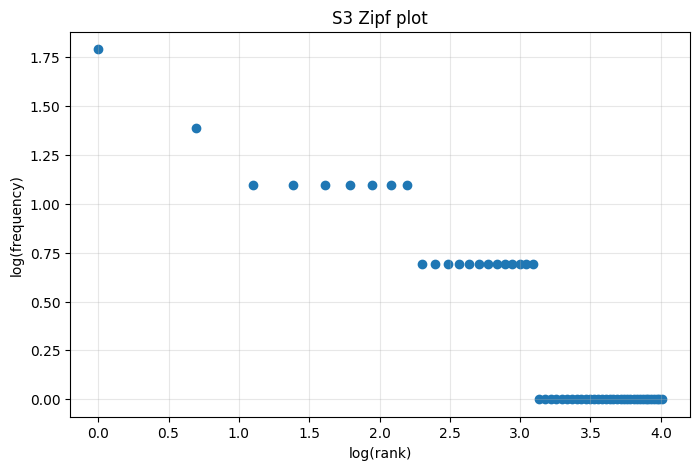

In [10]:
from collections import Counter
import matplotlib.pyplot as plt
S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for result in processed for token in result["tokens"] if token not in result["punct"]]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    return {"Corpus": name, "Total tokens": total, "Unique tokens": unique, "TTR": unique / total if total else 0}

stats_table = pd.DataFrame([corpus_stats(name, tokens) for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]])
display(stats_table)
print("Top 10 words of S1:", Counter(S1).most_common(10))
print("Top 10 words of S3:", Counter(S3).most_common(10))
print("Top 5 bigrams of S1:", Counter(zip(S1, S1[1:])).most_common(5))
print("Top 5 bigrams of S3:", Counter(zip(S3, S3[1:])).most_common(5))

import math
rank_frequency = sorted(Counter(S3).values(), reverse=True)
plt.figure(figsize=(8, 5))
plt.scatter([math.log(rank) for rank in range(1, len(rank_frequency) + 1)], [math.log(freq) for freq in rank_frequency])
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 Zipf plot")
plt.grid(True, alpha=0.3)
plt.show()


---
## Q6. Interpretation

Answer briefly using the computed outputs: (a) why TTR changes from S1 to S4, (b) one tokenizer difference, (c) one undesirable stemming result, and (d) one case where POS-aware lemmatization preserves meaning better than stemming.


In [11]:
s1_ttr = stats_table.loc[stats_table["Corpus"] == "S1", "TTR"].iloc[0]
s4_ttr = stats_table.loc[stats_table["Corpus"] == "S4", "TTR"].iloc[0]
print(f"(a) TTR changes from {s1_ttr:.3f} to {s4_ttr:.3f}. Stopword and punctuation removal reduce the token set, and Porter stemming can merge forms, changing the unique-to-total ratio.")

example = next(((ticket_id, text, my_tokenize(text), word_tokenize(text)) for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]) if my_tokenize(text) != word_tokenize(text)), None)
if example:
    ticket_id, example_text, custom, standard = example
    print(f"(b) In {ticket_id}, my_tokenize() and word_tokenize() differ on this generated ticket: {example_text}")
    print("Custom:", custom)
    print("word_tokenize():", standard)
else:
    print("(b) The test-line comparison above shows the tokenizer difference.")

undesirable = next(((word, lancaster.stem(word)) for word in unique_final_tokens if len(word) >= 5 and len(lancaster.stem(word)) <= 3 and lancaster.stem(word) != word), None)
if undesirable:
    print(f"(c) Lancaster turns {undesirable[0]!r} into {undesirable[1]!r}; the shortened stem is hard to recognize and loses meaning.")
else:
    print("(c) Inspect Lancaster and Porter results in the stem table for the most shortened output; a stemmer can produce fragments that are not valid words.")

lemma_case = next(((word, porter.stem(word), lemma(word)) for word in unique_final_tokens if porter.stem(word) != lemma(word)), None)
if lemma_case:
    print(f"(d) For {lemma_case[0]!r}, POS-aware lemmatization gives {lemma_case[2]!r}, while Porter gives {lemma_case[1]!r}. The POS tag helps preserve a dictionary form appropriate to its grammatical role.")
else:
    print("(d) No distinct Porter/lemma example occurred among these final tokens; compare the stem table for an inflected word whose lemma is more recognizable.")


(a) TTR changes from 0.461 to 0.578. Stopword and punctuation removal reduce the token set, and Porter stemming can merge forms, changing the unique-to-total ratio.
(b) In T01, my_tokenize() and word_tokenize() differ on this generated ticket: Password stopped responding since yesterday. It works on another computer.
Custom: ['Password', 'stopped', 'responding', 'since', 'yesterday', 'It', 'works', 'on', 'another', 'computer']
word_tokenize(): ['Password', 'stopped', 'responding', 'since', 'yesterday', '.', 'It', 'works', 'on', 'another', 'computer', '.']
(c) Lancaster turns 'asking' into 'ask'; the shortened stem is hard to recognize and loses meaning.
(d) For 'another', POS-aware lemmatization gives 'another', while Porter gives 'anoth'. The POS tag helps preserve a dictionary form appropriate to its grammatical role.
